# Textometria del corpus de sentencias de la Corte Constitucional de Colombia (1992-2021)

**Entrega 1 - Procesamiento de Lenguaje Natural**

**Pontificia Universidad Javeriana**

Notebook consolidado de analisis: parseo de metadatos, limpieza de texto, textometria global
(documentos, total de palabras, promedios, top-20 con y sin stopwords, nubes de palabras) sobre el
corpus completo, y anexo de muestra para el informe.

Ejecutado localmente (nucleo `python3`, venv local).

## 0. Requisitos, datos y reproducibilidad

**Ejecucion de principio a fin**: este notebook es autocontenido. Si falta la libreria
`wordcloud` o los datos de stopwords de NLTK, la celda de configuracion los instala o descarga
automaticamente; el CSV del corpus (~1,7 GB) tambien se descarga solo a `data/Juris1992_2022.csv`
la primera vez (requiere internet y el paquete `huggingface_hub`). Si ya se tiene el archivo, se
coloca en esa ruta y no se descarga nada.

**Dependencias**: Python >= 3.9 con `pandas`, `numpy`, `matplotlib`, `nltk` y `wordcloud`
(esta ultima se auto-instala si falta); `huggingface_hub` solo para la descarga del corpus.

**Dataset**: `Manuel/sentencias-corte-cons-colombia-1992-2021` (licencia CC-BY-4.0):
<https://huggingface.co/datasets/Manuel/sentencias-corte-cons-colombia-1992-2021>

**Duracion**: la pasada completa sobre las 23.742 sentencias tarda ~5-6 min en CPU (la celda 7
imprime progreso cada 5.000 filas) y la segunda lectura del anexo ~2-3 min.

**Salidas** (todas relativas al directorio del notebook): `figuras/*.png`,
`resultados/metricas.json`, `data/procesado/df_metadatos.csv` y `data/anexo_corpus_muestra.csv`.
Semilla fija 42 para el anexo y las nubes.

## 1. Contexto y carga del corpus

**Fuente y licencia.** El corpus es el dataset `Manuel/sentencias-corte-cons-colombia-1992-2021`
publicado en Hugging Face Hub (https://huggingface.co/datasets/Manuel/sentencias-corte-cons-colombia-1992-2021),
que recopila sentencias de la relatoria de la Corte Constitucional de Colombia entre 1992 y 2021.
La licencia declarada es CC-BY-4.0. Nota: el archivo del repositorio se llama `Juris1992_2022.csv`, pero la cobertura real de sentencias es 1992-2021 (2021 es parcial: solo 20 documentos) y no hay sentencias de 2022.

**Formato.** Un unico archivo CSV en UTF-8 de ~1,68 GB con dos columnas: `''` (identificador
consecutivo) y `Texto` (la sentencia completa). Hay **23.750 documentos**. Los campos `Texto` son
muy grandes (una sola sentencia puede superar los 3 MB y decenas de miles de palabras), por lo que
la lectura se hace en streaming con `csv.reader` y `csv.field_size_limit` ampliado, sin cargar el
archivo completo en memoria.

**Alternativa en la nube (Colab).** El mismo archivo puede leerse sin descarga local desde
`hf://datasets/Manuel/sentencias-corte-cons-colombia-1992-2021/Juris1992_2022.csv`; en este
notebook se usa la copia local `data/Juris1992_2022.csv`.

In [1]:
# ============================================================
# Configuracion general, bootstrap de recursos y carga de librerias
# ============================================================
%matplotlib inline

import csv
import json
import os
import re
import subprocess
import sys
import time
import unicodedata
from collections import Counter
from datetime import date
from IPython.display import display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- Bootstrap NLTK: stopwords en espanol (descarga automatica si faltan) ---
try:
    from nltk.corpus import stopwords
    stopwords.words("spanish")          # dispara LookupError si los datos no existen
except (ImportError, LookupError):
    import nltk
    nltk.download("stopwords", quiet=True)
    from nltk.corpus import stopwords

# --- Bootstrap wordcloud (auto-instalacion si falta la libreria) ---
try:
    from wordcloud import WordCloud
except ImportError:
    print("wordcloud no esta instalado; instalando...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "wordcloud"])
    from wordcloud import WordCloud

# --- Rutas (relativas al directorio del proyecto) ---
RUTA_CSV = "data/Juris1992_2022.csv"
CARPETA_FIGURAS = "figuras"
CARPETA_RESULTADOS = "resultados"
CARPETA_PROCESADO = "data/procesado"
RUTA_DF_METADATOS = os.path.join(CARPETA_PROCESADO, "df_metadatos.csv")
RUTA_ANEXO = "data/anexo_corpus_muestra.csv"
RUTA_METRICAS = os.path.join(CARPETA_RESULTADOS, "metricas.json")

# --- Nombres de figuras de salida ---
FIG_SENTENCIAS_POR_ANIO = os.path.join(CARPETA_FIGURAS, "fig_sentencias_por_anio.png")
FIG_TOP20_CON = os.path.join(CARPETA_FIGURAS, "fig_top20_con_stopwords.png")
FIG_TOP20_SIN = os.path.join(CARPETA_FIGURAS, "fig_top20_sin_stopwords.png")
FIG_NUBE_GLOBAL = os.path.join(CARPETA_FIGURAS, "fig_nube_global.png")
FIG_NUBES_POR_ANIO = os.path.join(CARPETA_FIGURAS, "fig_nubes_por_anio.png")

# --- Parametros del analisis ---
LIMITE_CAMPO = 100_000_000        # bytes maximos por campo CSV (textos gigantes)
PASO_PROGRESO = 5000              # filas entre mensajes de progreso de la pasada
SEMILLA_ANEXO = 42                # semilla fija para la muestra del anexo
N_ANEXO = 25                      # documentos del anexo
N_ANEXO_POR_TIPO = {"T": 17, "C": 6, "SU": 2}
MIN_DOCS_NUBE_ANIO = 50           # minimo de documentos por anio para su nube
NUBE_GLOBAL_TOP = 5000            # terminos mas frecuentes que alimentan la nube global
NUBE_ANIO_TOP = 1000              # terminos por anio que alimentan cada nube anual
TOP_N = 20                        # numero de terminos del top-N global

# --- Bootstrap del dataset: descarga desde Hugging Face solo si falta ---
REPO_DATASET = "Manuel/sentencias-corte-cons-colombia-1992-2021"
ARCHIVO_DATASET = "Juris1992_2022.csv"


def asegurar_archivo_datos(ruta_csv):
    """Descarga el CSV del corpus desde Hugging Face si no existe en ruta_csv.

    La primera ejecucion en una maquina nueva descarga ~1,7 GB a la carpeta 'data'
    (requiere internet y huggingface_hub). Si el archivo ya existe, no hace nada.

    Args:
        ruta_csv: Ruta relativa esperada del CSV.

    Returns:
        La ruta confirmada del CSV.
    """
    if os.path.exists(ruta_csv):
        return ruta_csv
    print("No se encontro '{}': descargando el corpus desde Hugging Face (~1,7 GB, "
          "solo la primera vez)...".format(ruta_csv))
    try:
        from huggingface_hub import hf_hub_download
        carpeta_datos = os.path.dirname(ruta_csv) or "."
        os.makedirs(carpeta_datos, exist_ok=True)
        hf_hub_download(repo_id=REPO_DATASET, filename=ARCHIVO_DATASET,
                        repo_type="dataset", local_dir=carpeta_datos)
    except Exception as error:  # noqa: BLE001 - mensaje accionable para el usuario
        raise RuntimeError(
            "No fue posible descargar el corpus automaticamente. Descargalo a mano desde "
            "https://huggingface.co/datasets/Manuel/sentencias-corte-cons-colombia-1992-2021 "
            "(archivo Juris1992_2022.csv) y colocalo en '{}'. Error original: {}".format(
                ruta_csv, error)) from error
    return ruta_csv


RUTA_CSV = asegurar_archivo_datos(RUTA_CSV)

for carpeta in (CARPETA_FIGURAS, CARPETA_RESULTADOS, CARPETA_PROCESADO):
    os.makedirs(carpeta, exist_ok=True)

csv.field_size_limit(LIMITE_CAMPO)

print("Configuracion lista. Tamanio del archivo CSV: {:.2f} GB".format(
    os.path.getsize(RUTA_CSV) / 1e9))

Configuracion lista. Tamanio del archivo CSV: 1.68 GB


In [2]:
# ------------------------------------------------------------
# Muestra pequena y descripcion estructural del archivo
# ------------------------------------------------------------
with open(RUTA_CSV, "r", encoding="utf-8", newline="") as f:
    lector = csv.reader(f)
    encabezado = next(lector)
    muestra = [next(lector) for _ in range(3)]

print("Encabezado del CSV:", encabezado)
df_muestra = pd.DataFrame(muestra, columns=["id", "Texto"])
df_muestra["caracteres"] = df_muestra["Texto"].str.len()
df_muestra[["id", "caracteres"]].head()

print("Inicio de la primera sentencia del corpus:")
print(df_muestra.loc[0, "Texto"][:400])
print("...")
print("Total esperado de filas de datos: 23.750 (verificado en la pasada completa).")

Encabezado del CSV: ['', 'Texto']
Inicio de la primera sentencia del corpus:
T-001-21
Sentencia
T-001/21
Referencia: Expediente T-7.859.919.
Acción de tutela presentada por Francisco Javier Rincón Riaño como agente oficioso de
Jhon Geiler Moreno Valero contra Capital Salud E.P.S.-S.
Procedencia: Juzgado Cuarenta y Tres (43) Penal del
Circuito de Bogotá con Funciones de Conocimiento.
Asunto: agencia
oficiosa, derecho a la rehabilitación de las personas en situación de
disca
...
Total esperado de filas de datos: 23.750 (verificado en la pasada completa).


## 2. Parseo de metadatos (tipo, numero y anio)

Cada sentencia comienza con una clave de relatoria del tipo `T-001/21`, `C-123/19`,
`SU-397/21` o `SENTENCIA T-001/21`. Para extraerla de forma robusta se normaliza el texto
conservando digitos y se aplica la expresion regular:

`^(sentencia\s+)?([cts])(u)?\s*(\d{1,4})\s+(\d{2,4})`

- Grupo 1: tipo (`t`, `c` o `s` con `u` -> `SU`). El corpus solo contiene tipos **T**, **C** y **SU**.
- Grupo 2: numero de la sentencia (siempre de 3 digitos en este corpus).
- Grupo 3: anio con 2 digitos (o 4 en formatos atipicos). Regla de conversion: digitos 90-99 -> 19xx;
  digitos 00-21 -> 20xx (el corpus cubre 1992-2021; no hay documentos de 2022).

La normalizacion usada para el parseo (con digitos) es la misma base de la limpieza de la seccion 3:
minusculas, proteccion de la `n` con virgulilla, eliminacion de diacriticos (NFD), filtro de
caracteres y colapso de espacios.

In [3]:
# ============================================================
# Funciones de normalizacion, parseo y limpieza (definicion unica)
# ============================================================
PLACEHOLDER_N = "\u0001"  # centinela temporal para proteger la 'n' con virgulilla
PREFIJO_REGEX = re.compile(r"^(?:sentencia\s+)?([cts])(u)?\s*(\d{1,4})\s+(\d{2,4})")
MAPA_TIPO = {"t": "T", "c": "C", "s": "S"}


def normalizar(texto, con_digitos):
    """Normaliza un texto: minusculas, sin diacriticos y solo letras (y digitos).

    Pasos: minusculas; proteccion de la 'n' con virgulilla antes de descomponer en NFD;
    eliminacion de marcas de acentuacion (rango Unicode \\u0300-\\u036f); restauracion de la
    virgulilla; filtro de caracteres (letras a-z y 'n' con virgulilla, con o sin digitos) y
    colapso de espacios.

    Args:
        texto: Cadena original.
        con_digitos: True conserva digitos (necesario para parsear la clave); False los elimina
            (version final para el analisis lexico).

    Returns:
        Cadena normalizada sin espacios multiples ni espacios extremos.
    """
    s = texto.lower().replace("\u00f1", PLACEHOLDER_N)
    s = unicodedata.normalize("NFD", s)
    s = re.sub(r"[\u0300-\u036f]", "", s).replace(PLACEHOLDER_N, "\u00f1")
    patron = r"[^a-z\u00f10-9\s]" if con_digitos else r"[^a-z\u00f1\s]"
    s = re.sub(patron, " ", s)
    return re.sub(r"\s+", " ", s).strip()


def limpiar_texto(texto_normalizado):
    """Produce la version limpia final (sin digitos) a partir del texto normalizado.

    El texto normalizado con digitos solo contiene letras, digitos y espacios; basta retirar
    los digitos y colapsar los espacios resultantes para obtener la version de analisis.

    Args:
        texto_normalizado: Salida de normalizar(texto, con_digitos=True).

    Returns:
        Texto con unicamente letras [a-z] y 'n' con virgulilla, sin digitos.
    """
    return re.sub(r"\s+", " ", re.sub(r"\d", " ", texto_normalizado)).strip()


def interpretar_annio(digitos_annio):
    """Convierte los digitos del anio de la clave de relatoria a anio calendario.

    Args:
        digitos_annio: Cadena de 2 o 4 digitos capturada por la expresion regular.

    Returns:
        Anio como entero. Con 4 digitos se usa el valor directo; con 2 digitos se aplica la
        regla 90-99 -> 19xx y 00-21 -> 20xx (periodo real del corpus: 1992-2021).
    """
    if len(digitos_annio) == 4:
        return int(digitos_annio)
    valor = int(digitos_annio)
    return 1900 + valor if 90 <= valor <= 99 else 2000 + valor


def parsear_prefijo(texto_normalizado):
    """Extrae (tipo, numero, anio) de la clave de relatoria al inicio del texto.

    Args:
        texto_normalizado: Texto normalizado con digitos (salida de normalizar con
            con_digitos=True).

    Returns:
        Tupla (tipo, numero, anio) si el texto inicia con una clave valida de sentencia
        (p. ej. 't 001 21'), o None si no la tiene (documento no sentencia).
    """
    coincidencia = PREFIJO_REGEX.match(texto_normalizado)
    if coincidencia is None:
        return None
    if coincidencia.group(2):          # 's' seguida de 'u' -> sentencia de unificacion
        tipo = "SU"
    else:
        tipo = MAPA_TIPO[coincidencia.group(1)]
    numero = int(coincidencia.group(3))
    annio = interpretar_annio(coincidencia.group(4))
    return tipo, numero, annio


def construir_stopwords_gramaticales():
    """Construye el conjunto de stopwords gramaticales normalizado como el texto.

    Correccion del analisis previo: la lista de stopwords NLTK en espanol tiene 84 formas con
    tilde (de 313) que no se eliminaban tras normalizar el corpus sin diacriticos. Aqui se
    normaliza la propia lista con la misma transformacion (minusculas, sin tildes) y se
    descartan formas no alfabeticas; las colisiones (p. ej. 'el'/'el' acentuado) colapsan en
    un unico termino, quedando 306 formas efectivas.

    Returns:
        Set con las stopwords gramaticales normalizadas.
    """
    conjunto = set()
    for palabra in stopwords.words("spanish"):
        normalizada = normalizar(palabra, con_digitos=False)
        if re.fullmatch(r"[a-z\u00f1]+", normalizada):
            conjunto.add(normalizada)
    return conjunto


STOPW_GRAMATICALES = construir_stopwords_gramaticales()
print("Stopwords gramaticales NLTK espanol: 313 originales -> {} formas normalizadas.".format(
    len(STOPW_GRAMATICALES)))

ABREV_CITA = {"art"}  # abreviaturas de cita descartadas (p. ej. 'art. 45' -> 'art')


def filtrar_tokens(tokens):
    """Filtra tokens de ruido antes de contabilizar (se aplica en la pasada completa).

    Descarta los tokens de un solo caracter que no sean stopwords gramaticales (restos de las
    claves de relatoria 'T-001/21' -> 't' y de las citas de paginas 'p. 45' -> 'p') y las
    abreviaturas de cita registradas en ABREV_CITA ('art. 45' -> 'art'). Las palabras
    funcionales de una letra que si estan en las stopwords gramaticales (a, y, o, e) se
    conservan: el contador 'con stopwords' debe incluirlas y el 'sin stopwords' las retira.

    Args:
        tokens: Lista de tokens del texto limpio (seccion 3).

    Returns:
        Lista de tokens conservados (filtro aplicado en origen).
    """
    conservados = []
    for token in tokens:
        if token in ABREV_CITA:
            continue
        if len(token) == 1 and token not in STOPW_GRAMATICALES:
            continue
        conservados.append(token)
    return conservados

Stopwords gramaticales NLTK espanol: 313 originales -> 306 formas normalizadas.


### Pasada completa sobre el corpus (celda principal del analisis)

La siguiente celda recorre el CSV completo **en una unica pasada en streaming** (~5-15 min;
medida en esta maquina: ~5 min). Por cada documento normaliza, parsea la clave y, si es una
sentencia, actualiza:

1. contador global **con stopwords** (solo tokens alfabeticos, incluye stopwords gramaticales),
2. contador global **sin stopwords**,
3. contador **por anio sin stopwords** (30 anios; memoria acotada),
4. conteos por documento: palabras raw (`split()` del texto crudo), palabras limpias y
   stopwords, para el `df_metadatos` ligero que se guarda en `data/procesado/`.

No se guardan tokens por documento en memoria. La tokenizacion es el `split()` sobre el texto
limpio (no se usa `word_tokenize` de NLTK sobre todo el corpus: tras la limpieza, los tokens
son exactamente las palabras alfabeticas) y se documenta como decision de analisis.

Antes de contabilizar se aplica en origen un filtro de ruido (funcion `filtrar_tokens`, seccion 3): se descartan los tokens de un solo caracter que no son stopwords gramaticales (restos de las claves de relatoria `T-001/21` -> `t`, `C-123/19` -> `c` y de las citas de pagina `p. 45` -> `p`) y la abreviatura de cita `art`; todos los contadores y conteos por documento se calculan sobre los tokens ya filtrados.

Las 8 filas que no inician con clave de sentencia se excluyen del corpus de analisis y se
registran (6 autos de la Sala Plena con clave `A-xxx` y 2 filas con basura HTML).

In [4]:
# ============================================================
# PASADA COMPLETA: textometria del corpus (analisis principal)
# Duracion tipica: 5-15 minutos (medida ~5 min en esta maquina).
# ============================================================
inicio_pasada = time.time()
contador_con = Counter()          # tokens alfabeticos (incluye stopwords gramaticales)
contador_sin = Counter()          # tokens alfabeticos sin stopwords gramaticales
contador_por_anio = {}            # anio -> Counter (sin stopwords gramaticales)
registros = []                    # un dict ligero por documento (sin texto)
no_sentencias = []                # filas excluidas: (posicion_csv, comienzo del texto)
n_filas_csv = 0

with open(RUTA_CSV, "r", encoding="utf-8", newline="") as f:
    lector = csv.reader(f)
    encabezado = next(lector)
    for fila in lector:
        n_filas_csv += 1
        if n_filas_csv % PASO_PROGRESO == 0:
            print("  filas procesadas: {:>6,}  (tiempo acumulado {:.0f} s)".format(
                n_filas_csv, time.time() - inicio_pasada))
        texto_crudo = fila[1]
        n_raw = len(texto_crudo.split())
        normalizado = normalizar(texto_crudo, con_digitos=True)
        metadatos = parsear_prefijo(normalizado)
        if metadatos is None:
            no_sentencias.append((n_filas_csv - 1, texto_crudo[:140].replace("\n", " ")))
            continue
        tipo, numero, annio = metadatos
        limpio = limpiar_texto(normalizado)
        # Filtro de ruido en origen: tokens de 1 letra no gramaticales y abreviaturas de cita
        tokens = filtrar_tokens(limpio.split())
        n_clean = len(tokens)
        n_stopwords = 0
        for token in tokens:
            contador_con[token] += 1
            if token in STOPW_GRAMATICALES:
                n_stopwords += 1
            else:
                contador_sin[token] += 1
                contador_por_anio.setdefault(annio, Counter())[token] += 1
        registros.append({
            "id": fila[0], "tipo": tipo, "numero": numero, "annio": annio,
            "n_palabras_raw": n_raw, "n_palabras_clean": n_clean,
            "n_stopwords": n_stopwords,
        })

tiempo_pasada = time.time() - inicio_pasada

# --- Consistencia interna de los contadores ---
df_metadatos = pd.DataFrame(registros)
assert sum(df_metadatos["n_palabras_clean"]) == sum(contador_con.values())
assert sum(df_metadatos["n_palabras_clean"]) - sum(df_metadatos["n_stopwords"]) == sum(contador_sin.values())
assert sum(v for c in contador_por_anio.values() for v in c.values()) == sum(contador_sin.values())

# --- Guardado del df ligero (agregados por documento, sin texto) ---
df_metadatos.to_csv(RUTA_DF_METADATOS, index=False, encoding="utf-8")

print()
print("Pasada completada: {:,} filas CSV leidas en {:.1f} s ({}).".format(
    n_filas_csv, tiempo_pasada, time.strftime("%M:%S", time.gmtime(tiempo_pasada))))
print("df_metadatos guardado en {} ({} documentos, sin texto).".format(
    RUTA_DF_METADATOS, len(df_metadatos)))

  filas procesadas:  5,000  (tiempo acumulado 32 s)


  filas procesadas: 10,000  (tiempo acumulado 72 s)


  filas procesadas: 15,000  (tiempo acumulado 131 s)


  filas procesadas: 20,000  (tiempo acumulado 231 s)



Pasada completada: 23,750 filas CSV leidas en 311.5 s (05:11).
df_metadatos guardado en data/procesado/df_metadatos.csv (23742 documentos, sin texto).


Tasa de parseo real: 23,742 / 23,750 = 99.9663%

df_metadatos: shape (23742, 7), columnas: ['id', 'tipo', 'numero', 'annio', 'n_palabras_raw', 'n_palabras_clean', 'n_stopwords']

  id tipo  numero  annio  n_palabras_raw  n_palabras_clean  n_stopwords
0  0    T       1   2021           21902             20639         9754
1  1    T       2   2021           27549             26275        12723
2  2    T      15   2021            8206              7746         3680
3  3    T      17   2021           15248             14285         6876
4  4    T      19   2021           14873             14097         7150

         annio  n_palabras_raw  n_palabras_clean  n_stopwords
count  23742.0         23742.0           23742.0      23742.0
mean    2006.3         10992.7           10530.4       5105.1
std        7.5         13597.2           13039.7       6320.7
min     1992.0           354.0             315.0        114.0
25%     2000.0          4148.0            3983.2       1919.0
50%     2006.0  

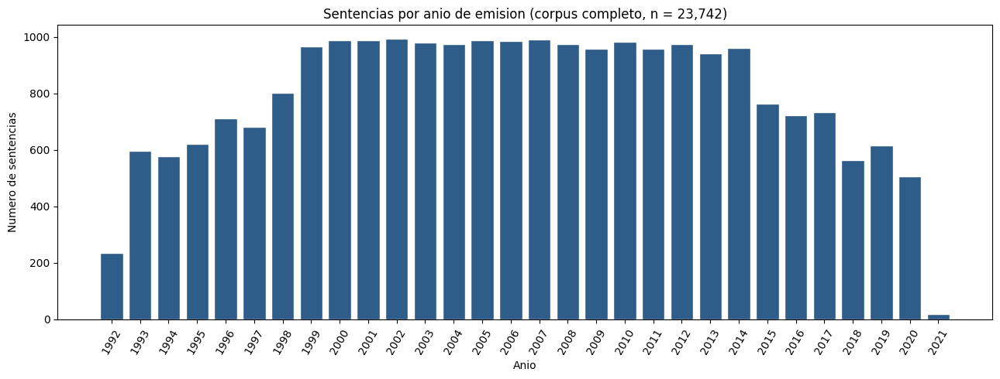

Figura guardada: figuras/fig_sentencias_por_anio.png


In [5]:
# ------------------------------------------------------------
# Resultados del parseo: tasa, exclusiones y distribuciones
# ------------------------------------------------------------
n_parseados = len(df_metadatos)
n_excluidos = len(no_sentencias)
tasa_parseo = n_parseados / n_filas_csv

print("Tasa de parseo real: {:,} / {:,} = {:.4%}".format(n_parseados, n_filas_csv, tasa_parseo))
print()
print("df_metadatos: shape {}, columnas: {}".format(df_metadatos.shape, list(df_metadatos.columns)))
print()
print(df_metadatos.head())
print()
print(df_metadatos[["annio", "n_palabras_raw", "n_palabras_clean", "n_stopwords"]]
      .describe().round(1))

# --- Filas excluidas (no sentencias), con clasificacion del motivo ---
def clasificar_no_sentencia(comienzo_texto):
    """Clasifica el motivo de exclusion de una fila no parseada.

    Args:
        comienzo_texto: Primeros caracteres del texto crudo.

    Returns:
        'auto' si el texto corresponde a un auto (clave A-xxx), 'basura_html' si contiene
        marcado script, o 'no_clasificado' en otro caso.
    """
    bajo = comienzo_texto.lower()
    if "<script" in bajo:
        return "basura_html"
    if "auto" in bajo:
        return "auto"
    return "no_clasificado"

excluidos = pd.DataFrame(no_sentencias, columns=["posicion_csv", "comienzo_texto"])
excluidos["motivo"] = excluidos["comienzo_texto"].apply(clasificar_no_sentencia)
print()
print("Documentos excluidos del corpus de analisis ({}):".format(n_excluidos))
print(excluidos[["posicion_csv", "motivo", "comienzo_texto"]])

# --- Distribucion por tipo de sentencia ---
print()
print("Distribucion por tipo de sentencia:")
print(df_metadatos["tipo"].value_counts().rename_axis("tipo").to_frame("documentos"))

# --- Distribucion por anio: tabla y grafico de barras ---
docs_por_anio = df_metadatos.groupby("annio").size()
tabla_anios = docs_por_anio.rename_axis("annio").to_frame("documentos")
print()
print("Documentos por anio de emision:")
print(tabla_anios)

plt.figure(figsize=(13, 5))
plt.bar(tabla_anios.index, tabla_anios["documentos"], color="#2f5d8a", edgecolor="white")
plt.title("Sentencias por anio de emision (corpus completo, n = {:,})".format(n_parseados))
plt.xlabel("Anio")
plt.ylabel("Numero de sentencias")
plt.xticks(tabla_anios.index, rotation=60)
plt.tight_layout()
plt.savefig(FIG_SENTENCIAS_POR_ANIO, dpi=150, bbox_inches="tight")
plt.show()
print("Figura guardada:", FIG_SENTENCIAS_POR_ANIO)

## 3. Limpieza basica del texto

La limpieza aplicada a cada documento (funciones `normalizar` y `limpiar_texto` de la
seccion 2) consta de los siguientes pasos, en orden:

1. **Minusculas**: unifica la escritura (`Sentencia` y `SENTENCIA` pasan a `sentencia`).
2. **Proteccion de la `n` con virgulilla**: se reemplaza `n` por un centinela antes de
   descomponer, para que no se convierta en `n` + tilde suelta (la `n` con virgulilla es una
   letra propia del espanol y debe conservarse).
3. **Eliminacion de diacriticos (NFD)**: se descompone cada caracter en su forma base + marca
   de acentuacion y se retiran las marcas del rango Unicode `\u0300-\u036f`; luego se restaura
   la virgulilla protegida. Asi `accion`, `CONSTITUCION` y `artículo` quedan como `accion`,
   `constitucion` y `articulo`.
4. **Filtro de caracteres**: en la version final (sin digitos) solo se conservan las letras
   `[a-z]` y la `n` con virgulilla; todo lo demas (numeros, puntuacion, simbolos, fechas,
   claves de expediente) se convierte en espacio. Para el parseo se conserva ademas `[0-9]`.
5. **Colapso de espacios**: se reduce cualquier serie de espacios a uno y se eliminan los
   extremos.

**Tokenizacion**: tras la limpieza, el texto contiene unicamente palabras alfabeticas
separadas por un espacio, de modo que `split()` es una tokenizacion exacta y determinista; no
se requiere (ni se usa, por costo) `word_tokenize` de NLTK sobre todo el corpus.

Sobre los tokens se aplica ademas un **filtro de ruido en origen** (funcion `filtrar_tokens`): se descartan los tokens de un solo caracter que no sean stopwords
gramaticales (restos de las claves de relatoria `T-001/21` -> `t` y `C-123/19` -> `c`,
y de las citas de paginas `p. 45` -> `p`) y las abreviaturas de cita de la lista
`ABREV_CITA = {"art"}` (`art. 45` -> `art`). Las vocales funcionales de una letra que
si son stopwords gramaticales (`a`, `y`, `o`, `e`) se conservan. Como el filtro se
aplica antes de contabilizar, todas las cifras del analisis (contadores y conteos por
documento) ya vienen sin ese ruido.

In [6]:
# ------------------------------------------------------------
# Demostracion de la limpieza sobre un fragmento real
# ------------------------------------------------------------
fragmento = df_muestra.loc[0, "Texto"][:280]
limpio = limpiar_texto(normalizar(fragmento, con_digitos=True))
print("FRAGMENTO ORIGINAL:")
print(fragmento)
print()
print("TEXTO LIMPIO (minusculas, sin tildes, solo letras):")
print(limpio)
print()
print("Tokens tras el filtro de ruido (filtrar_tokens):", filtrar_tokens(limpio.split()))
print()
print("Nota: la clave de relatoria 'T-001-21' deja el token suelto 't' y las citas de pagina")
print("'p. 45' dejarian 'p'; el filtro de ruido los descarta en origen junto con la")
print("abreviatura 'art', por lo que no entran a los contadores del analisis (seccion 5).")

FRAGMENTO ORIGINAL:
T-001-21
Sentencia
T-001/21
Referencia: Expediente T-7.859.919.
Acción de tutela presentada por Francisco Javier Rincón Riaño como agente oficioso de
Jhon Geiler Moreno Valero contra Capital Salud E.P.S.-S.
Procedencia: Juzgado Cuarenta y Tres (43) Penal del
Circuito de Bogotá co

TEXTO LIMPIO (minusculas, sin tildes, solo letras):
t sentencia t referencia expediente t accion de tutela presentada por francisco javier rincon riaño como agente oficioso de jhon geiler moreno valero contra capital salud e p s s procedencia juzgado cuarenta y tres penal del circuito de bogota co

Tokens tras el filtro de ruido (filtrar_tokens): ['sentencia', 'referencia', 'expediente', 'accion', 'de', 'tutela', 'presentada', 'por', 'francisco', 'javier', 'rincon', 'riaño', 'como', 'agente', 'oficioso', 'de', 'jhon', 'geiler', 'moreno', 'valero', 'contra', 'capital', 'salud', 'e', 'procedencia', 'juzgado', 'cuarenta', 'y', 'tres', 'penal', 'del', 'circuito', 'de', 'bogota', 'co']

Nota: l

## 4. Textometria global

Con los agregados de la pasada completa se resume el corpus de analisis (las 23.742
sentencias parseadas; las 8 filas excluidas se documentaron en la seccion 2). Las cifras se
guardan al final del notebook en `resultados/metricas.json`.

- **Palabras raw**: conteo por `split()` del texto crudo (incluye numeros, claves y
  puntuacion separada por espacios).
- **Palabras limpias**: tokens alfabeticos resultantes de la limpieza (seccion 3), que
  incluyen las stopwords gramaticales.
- **Stopwords**: tokens limpios que pertenecen al conjunto gramatical normalizado (306
  formas).
- **Palabras sin stopwords**: diferencia entre las dos anteriores (base del analisis de
  contenido).

In [7]:
# ------------------------------------------------------------
# Resumen de textometria global del corpus de analisis
# ------------------------------------------------------------
def formatear_numero(valor):
    """Formatea un numero entero con separador de miles en espanol (punto)."""
    return "{:,}".format(int(valor)).replace(",", ".")

total_raw = int(df_metadatos["n_palabras_raw"].sum())
total_clean = int(df_metadatos["n_palabras_clean"].sum())
total_stopwords = int(df_metadatos["n_stopwords"].sum())
total_sin_stopwords = total_clean - total_stopwords
prom_raw = total_raw / n_parseados
prom_clean = total_clean / n_parseados
prom_sin = total_sin_stopwords / n_parseados
anio_min, anio_max = int(df_metadatos["annio"].min()), int(df_metadatos["annio"].max())

resumen = pd.DataFrame({
    "metrica": [
        "Documentos (sentencias parseadas)", "Total de palabras (raw)",
        "Total de palabras (limpias)", "Total de stopwords gramaticales",
        "Total de palabras sin stopwords", "Promedio de palabras raw por documento",
        "Promedio de palabras limpias por documento",
        "Promedio de palabras sin stopwords por documento",
        "Vocabulario unico (sin stopwords)", "Rango de anios",
    ],
    "valor": [
        "{:,}".format(n_parseados), formatear_numero(total_raw),
        formatear_numero(total_clean), formatear_numero(total_stopwords),
        formatear_numero(total_sin_stopwords),
        "{:,.1f}".format(prom_raw).replace(",", " "),
        "{:,.1f}".format(prom_clean).replace(",", " "),
        "{:,.1f}".format(prom_sin).replace(",", " "),
        formatear_numero(len(contador_sin)),
        "{} - {}".format(anio_min, anio_max),
    ],
})
display(resumen)

# Referencia para metricas.json: total raw calculado y diferencia con el valor previo
total_previo_estimado = 271_907_978
print("Total palabras raw calculado: {} (valor previo estimado por extrapolacion: {};"
      " diferencia de {} palabras, -{:.1f}%).".format(
          formatear_numero(total_raw), formatear_numero(total_previo_estimado),
          formatear_numero(total_previo_estimado - total_raw),
          100 * (total_previo_estimado - total_raw) / total_previo_estimado))
print("Proporcion de stopwords gramaticales sobre palabras limpias: {:.1%}.".format(
    total_stopwords / total_clean))

,metrica,valor
0,Documentos (sentencias parseadas),"23,742"
1,Total de palabras (raw),260.988.316
2,Total de palabras (limpias),250.012.101
3,Total de stopwords gramaticales,121.205.437
4,Total de palabras sin stopwords,128.806.664
5,Promedio de palabras raw por documento,10 992.7
6,Promedio de palabras limpias por documento,10 530.4
7,Promedio de palabras sin stopwords por documento,5 425.3
8,Vocabulario unico (sin stopwords),224.202
9,Rango de anios,1992 - 2021


Total palabras raw calculado: 260.988.316 (valor previo estimado por extrapolacion: 271.907.978; diferencia de 10.919.662 palabras, -4.0%).
Proporcion de stopwords gramaticales sobre palabras limpias: 48.5%.


## 5. Top-20 global de palabras (con y sin stopwords)

Se muestran los 20 tokens mas frecuentes del corpus completo (no de una muestra). El top-20
"con stopwords" evidencia el peso de las palabras funcionales del espanol (articulos,
preposiciones, conjunciones): solo se consideran tokens alfabeticos (se excluyen los
tokens numericos puros, que en la version limpia ya no existen). El top-20 "sin stopwords"
deja ver el vocabulario juridico de contenido. Los tokens de ruido de una sola letra que un
analisis sin filtro reportaria en puestos altos (`t` y `c`, restos de las claves de relatoria
`T-001/21` / `C-123/19`, y `p`, resto de las citas de paginas `p. 45`) ya no aparecen: el
filtro de ruido los descarta en origen (seccion 3), junto con la abreviatura de cita `art`,
antes de construir los contadores.

Top-20 global CON stopwords (tokens alfabeticos; total 250,012,101):
       frecuencia_con  porcentaje
token                            
de           22543375       9.017
la           14299738       5.720
el            8225551       3.290
que           7505218       3.002
en            7208184       2.883
y             5815750       2.326
a             5124736       2.050
del           4670179       1.868
los           4196533       1.679
se            3485410       1.394
por           3315608       1.326
las           3088387       1.235
no            2267665       0.907
para          2101076       0.840
con           1880905       0.752
al            1856725       0.743
su            1577454       0.631
un            1463000       0.585
o             1451831       0.581
una           1415694       0.566

Top-20 global SIN stopwords gramaticales (total 128,806,664):
                frecuencia_sin  porcentaje
token                                     
articulo                947616    

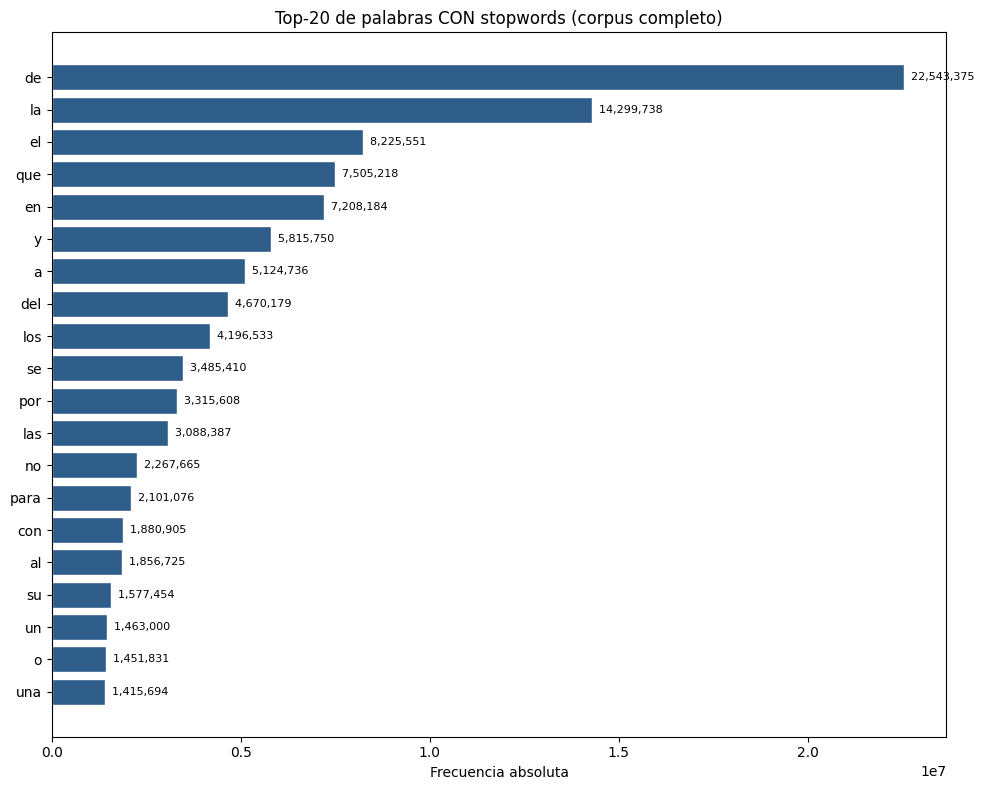

Figura guardada: figuras/fig_top20_con_stopwords.png


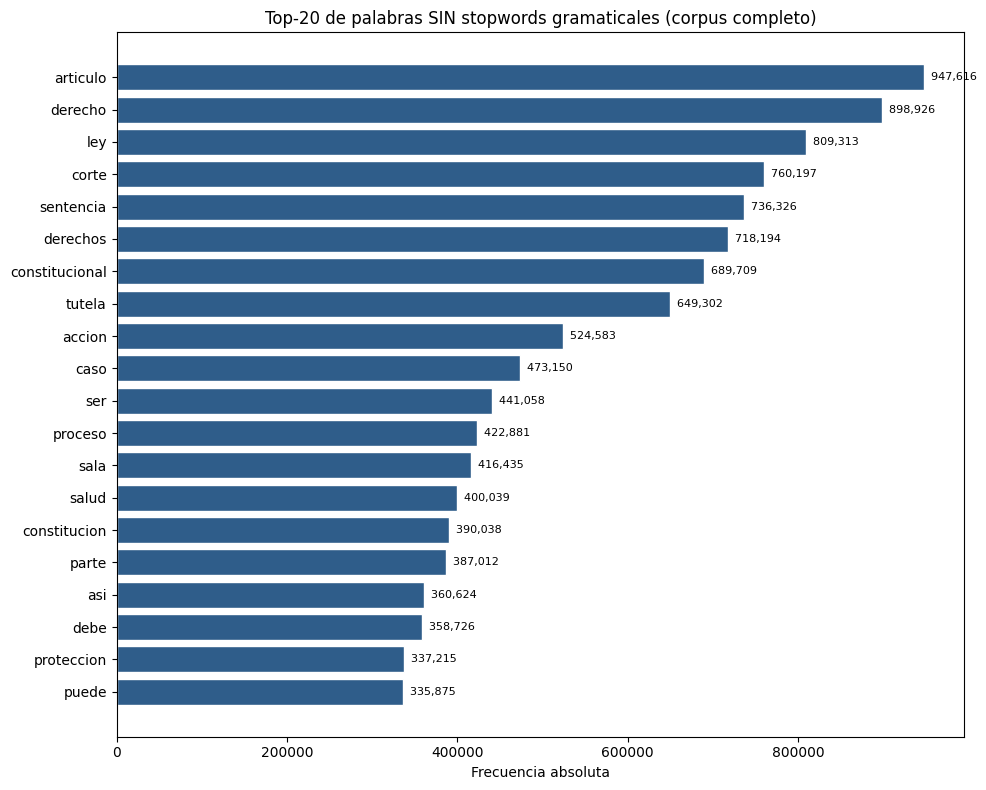

Figura guardada: figuras/fig_top20_sin_stopwords.png


In [8]:
# ------------------------------------------------------------
# Top-20 con y sin stopwords (tablas, pantalla y figuras)
# ------------------------------------------------------------
def tabla_top(tokens_top, total_denominador, nombre):
    """Construye el DataFrame del top-N con frecuencia y porcentaje del total.

    Args:
        tokens_top: Lista de pares (token, frecuencia) ya ordenada.
        total_denominador: Total de tokens sobre el que se calcula el porcentaje.
        nombre: Nombre de la columna de frecuencia (para encabezado legible).

    Returns:
        DataFrame con columnas 'token', nombre y 'porcentaje'.
    """
    filas = [{"token": token, nombre: frec, "porcentaje": 100.0 * frec / total_denominador}
             for token, frec in tokens_top]
    return pd.DataFrame(filas).set_index("token")


top_con = contador_con.most_common(TOP_N)
top_sin = contador_sin.most_common(TOP_N)
tabla_con = tabla_top(top_con, total_clean, "frecuencia_con")
tabla_sin = tabla_top(top_sin, total_sin_stopwords, "frecuencia_sin")

print("Top-{} global CON stopwords (tokens alfabeticos; total {:,}):".format(
    TOP_N, sum(contador_con.values())))
print(tabla_con.round(3))
print()
print("Top-{} global SIN stopwords gramaticales (total {:,}):".format(
    TOP_N, sum(contador_sin.values())))
print(tabla_sin.round(3))


def grafico_top(tabla, titulo, ruta_figura):
    """Genera el grafico de barras horizontales del top-N.

    Args:
        tabla: DataFrame con columna de frecuencia (unica columna numerica ademas del indice).
        titulo: Titulo del grafico.
        ruta_figura: Ruta PNG de salida.
    """
    frecuencias = tabla.iloc[:, 0]
    orden = frecuencias.sort_values()
    plt.figure(figsize=(10, 8))
    plt.barh(orden.index.astype(str), orden.values, color="#2f5d8a", edgecolor="white")
    for y, (token, valor) in enumerate(orden.items()):
        plt.text(valor, y, "  {:,}".format(int(valor)), va="center", fontsize=8)
    plt.title(titulo)
    plt.xlabel("Frecuencia absoluta")
    plt.tight_layout()
    plt.savefig(ruta_figura, dpi=150, bbox_inches="tight")
    plt.show()
    print("Figura guardada:", ruta_figura)


grafico_top(tabla_con, "Top-{} de palabras CON stopwords (corpus completo)".format(TOP_N),
            FIG_TOP20_CON)
grafico_top(tabla_sin, "Top-{} de palabras SIN stopwords gramaticales (corpus completo)".format(TOP_N),
            FIG_TOP20_SIN)

## 6. Nubes de palabras

(a) **Nube global**: sobre las frecuencias del corpus completo se retiran las stopwords
gramaticales y, ademas, una lista de **stopwords de dominio juridico** de alta frecuencia que
son parte del lenguaje administrativo de la corte y no aportan a la visualizacion del
contenido: `sentencia`, `corte`, `constitucional`, `derecho`, `justicia`, `tribunal`,
`magistrado`, `ponente`, `demanda`, `expediente`, `colombia`, `bogota`, `republica` y formas
procedimentales anexas. La lista es visible en la celda siguiente. Se alimenta con los 5.000
terminos mas frecuentes (decision de eficiencia: los terminos restantes son invisibles
a escala de la nube). Los contadores de las nubes ya vienen filtrados en origen
(seccion 3: sin tokens de una letra no gramaticales ni abreviaturas de cita).

(b) **Nubes por anio de emision**: una nube por anio con el top-1000 de su contador anual
(sin stopwords gramaticales). Se excluyen los anios con menos de 50 documentos (en este
corpus solo 2021, con 20; 1992 cuenta con 234 y si se incluye).

Stopwords gramaticales: 306 formas; stopwords de dominio juridico: 65 formas.
Terminos que alimentan la nube global: 4936


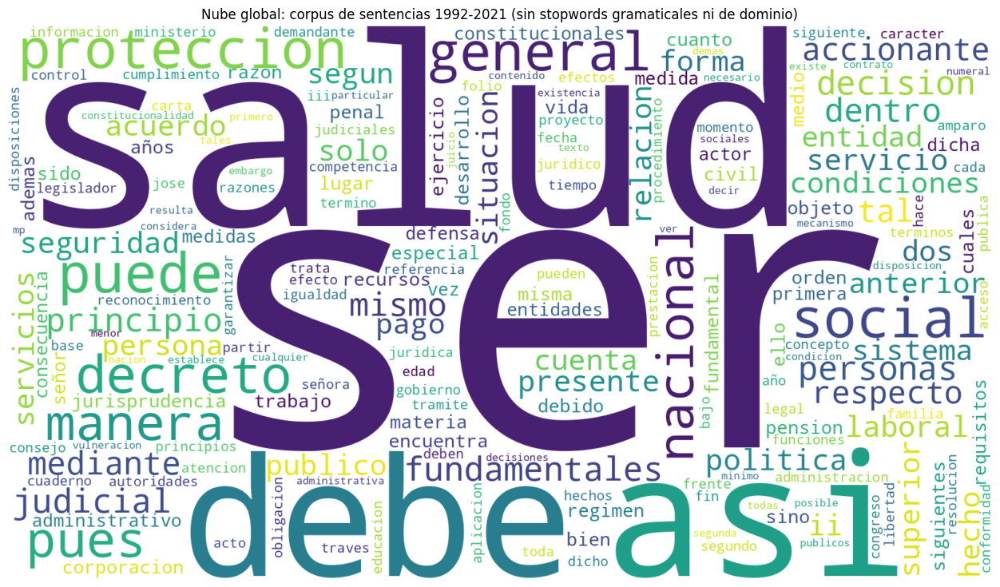

Figura guardada: figuras/fig_nube_global.png


In [9]:
# ------------------------------------------------------------
# (a) Nube global de palabras (con stopwords de dominio juridico)
# ------------------------------------------------------------
STOPW_DOMINIO_JURIDICO = [
    "sentencia", "sentencias", "corte", "constitucional", "constitucion", "derecho",
    "derechos", "justicia", "tribunal", "magistrado", "magistrados", "ponente", "demanda",
    "demandas", "expediente", "expedientes", "colombia", "bogota", "republica", "accion",
    "acciones", "tutela", "tutelas", "articulo", "articulos", "ley", "leyes", "norma",
    "normas", "codigo", "auto", "autos", "proceso", "procesos", "providencia",
    "providencias", "fallo", "fallos", "sala", "plena", "parte", "partes", "juez",
    "juzgado", "despacho", "relatoria", "secretaria", "actuacion", "actuaciones", "cargo",
    "cargos", "asunto", "asuntos", "caso", "casos", "tema", "temas", "prueba", "pruebas",
    "peticion", "solicitud", "solicitudes", "revision", "instancia", "instancias",
]
print("Stopwords gramaticales: {} formas; stopwords de dominio juridico: {} formas.".format(
    len(STOPW_GRAMATICALES), len(STOPW_DOMINIO_JURIDICO)))

# El contador ya viene filtrado en origen (seccion 3); aqui solo se excluyen las
# stopwords de dominio juridico, sin guards adicionales.
frecuencias_nube = {
    token: frec for token, frec in contador_sin.most_common(NUBE_GLOBAL_TOP)
    if token not in STOPW_DOMINIO_JURIDICO
}
print("Terminos que alimentan la nube global:", len(frecuencias_nube))

nube_global = WordCloud(
    width=1600, height=900, background_color="white", colormap="viridis",
    random_state=SEMILLA_ANEXO, collocations=False,
).generate_from_frequencies(frecuencias_nube)

plt.figure(figsize=(16, 9))
plt.imshow(nube_global, interpolation="bilinear")
plt.axis("off")
plt.title("Nube global: corpus de sentencias 1992-2021 (sin stopwords gramaticales ni de dominio)")
plt.savefig(FIG_NUBE_GLOBAL, dpi=150, bbox_inches="tight")
plt.show()
print("Figura guardada:", FIG_NUBE_GLOBAL)

Anios con nube (29 >= 50 docs): 1992 a 2020
Anios excluidos de la grilla (menos de 50 documentos): [2021]


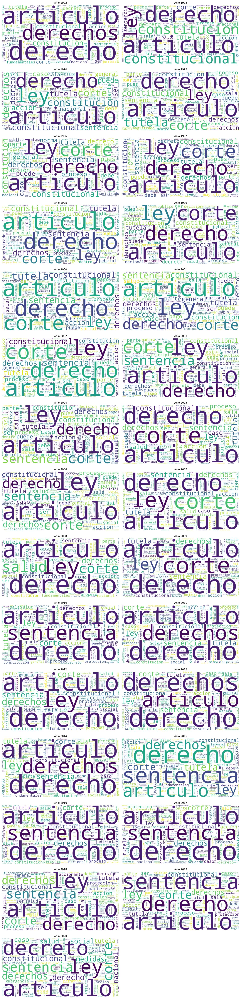

Figura guardada: figuras/fig_nubes_por_anio.png


In [10]:
# ------------------------------------------------------------
# (b) Nubes por anio de emision (grilla de 2 columnas)
# ------------------------------------------------------------
anios_con_nube = [a for a in sorted(contador_por_anio)
                  if len(df_metadatos[df_metadatos["annio"] == a]) >= MIN_DOCS_NUBE_ANIO]
anios_excluidos = sorted(set(contador_por_anio) - set(anios_con_nube))
print("Anios con nube ({:,} >= {} docs): {} a {}".format(
    len(anios_con_nube), MIN_DOCS_NUBE_ANIO, anios_con_nube[0], anios_con_nube[-1]))
print("Anios excluidos de la grilla (menos de {} documentos): {}".format(
    MIN_DOCS_NUBE_ANIO, anios_excluidos))

n_filas_grilla = -(-len(anios_con_nube) // 2)  # redondeo hacia arriba
fig, ejes = plt.subplots(n_filas_grilla, 2, figsize=(16, 4.4 * n_filas_grilla))
ejes = ejes.ravel()

for pos, anio in enumerate(anios_con_nube):
    frecuencias_anio = dict(contador_por_anio[anio].most_common(NUBE_ANIO_TOP))
    nube_anio = WordCloud(
        width=900, height=450, background_color="white", colormap="viridis",
        random_state=SEMILLA_ANEXO, collocations=False,
    ).generate_from_frequencies(frecuencias_anio)
    ejes[pos].imshow(nube_anio, interpolation="bilinear")
    ejes[pos].axis("off")
    ejes[pos].set_title("Anio {}".format(anio))

for extra in range(len(anios_con_nube), len(ejes)):
    ejes[extra].axis("off")

plt.tight_layout()
plt.savefig(FIG_NUBES_POR_ANIO, dpi=120, bbox_inches="tight")
plt.show()
print("Figura guardada:", FIG_NUBES_POR_ANIO)

## 7. Anexo de corpus (muestra para el informe)

Se genera `data/anexo_corpus_muestra.csv` con 25 sentencias del corpus parseado (mezcla de
tipos T, C y SU: 17 tutelas, 6 constitucionalidad y 2 unificacion, con semilla fija 42 para
reproducibilidad). El archivo conserva el texto completo y las columnas de metadatos
`id`, `tipo`, `numero`, `annio`, y sirve de insumo al apendice del informe. La celda
siguiente recarga el df ligero guardado en `data/procesado/` (con `id` convertido a
texto) y hace una **segunda pasada de lectura del CSV (~2-3 min)** para extraer el
texto completo de los documentos elegidos.

In [11]:
# ------------------------------------------------------------
# Seleccion de la muestra (semilla fija) y extraccion del texto completo
# ------------------------------------------------------------
rng = np.random.default_rng(SEMILLA_ANEXO)
assert sum(N_ANEXO_POR_TIPO.values()) == N_ANEXO

# Se recarga el df ligero guardado por la pasada; 'id' se fuerza a texto (str) porque el CSV
# lo recuperaria como entero y la comparacion contra las claves de la segunda lectura exige
# el mismo tipo de dato.
df_metadatos_recargado = pd.read_csv(RUTA_DF_METADATOS, dtype={"id": str})
assert (df_metadatos_recargado["id"] == df_metadatos["id"]).all(), "ids desincronizados"

filas_elegidas = set()
for tipo, cantidad in N_ANEXO_POR_TIPO.items():
    candidatas = df_metadatos_recargado.loc[df_metadatos_recargado["tipo"] == tipo,
                                            "id"].to_numpy()
    filas_elegidas.update(rng.choice(candidatas, size=cantidad, replace=False).tolist())
print("Documentos elegidos para el anexo: {} (ids de ejemplo: {})".format(
    len(filas_elegidas), sorted(filas_elegidas)[:6]))

# Segunda pasada de lectura del CSV (~2-3 min): extrae el texto completo de los elegidos.
ids_por_tipo = df_metadatos_recargado.set_index("id")
with open(RUTA_CSV, "r", encoding="utf-8", newline="") as f_entrada:
    with open(RUTA_ANEXO, "w", encoding="utf-8", newline="") as f_salida:
        escritor = csv.writer(f_salida)
        escritor.writerow(["id", "tipo", "numero", "annio", "Texto"])
        lector = csv.reader(f_entrada)
        encabezado = next(lector)
        for fila in lector:
            if fila[0] in filas_elegidas:
                meta = ids_por_tipo.loc[fila[0]]
                escritor.writerow([fila[0], meta["tipo"], int(meta["numero"]),
                                   int(meta["annio"]), fila[1]])

df_anexo = pd.read_csv(RUTA_ANEXO, dtype={"id": str})
assert len(df_anexo) == N_ANEXO, "el anexo debe tener exactamente N_ANEXO filas"
assert set(df_anexo["id"]) == filas_elegidas, "ids del anexo no coinciden con los elegidos"
pd.set_option("display.max_colwidth", 140)
print("Anexo guardado en {} con {} documentos.".format(RUTA_ANEXO, len(df_anexo)))
print(df_anexo[["id", "tipo", "numero", "annio", "Texto"]].head(8))

Documentos elegidos para el anexo: 25 (ids de ejemplo: ['10673', '10773', '11939', '12518', '12742', '1379'])


Anexo guardado en data/anexo_corpus_muestra.csv con 25 documentos.
      id tipo  numero  annio  \
0   1379    C     227   1993   
1   2195    T     293   1997   
2   2251    T     376   1997   
3   2336    T     543   1997   
4   2721   SU     476   1997   
5   5125    C     448   1998   
6   5326    T     140   1999   
7  10673    T     750   2004   

                                                                                                                                         Texto  
0  C-227-93\nSentencia No\nSentencia No.\nC-227/93\nTRATADO\nINTERNACIONAL-Reserva\nSi el Congreso puede aprobar o improbar todo un tratado...  
1  T-293-97\nSentencia T-293/97\nSentencia\nT-293/97\nACCION DE TUTELA-No sustituye sistema jurídico ordinario\nLa acción de\ntutela es mec...  
2  T-376-97\nSentencia T-376/97\nSentencia T-376/97\nSERVICIO MILITAR-Titularidad de derechos constitucionales\nLos nacionales que presten ...  
3  T-543-97\nSentencia T- 543 /97\nSentencia T- 543 /97\nDERECHO

In [12]:
# ------------------------------------------------------------
# Fragmentos representativos del anexo (inicio de una T y de una C/SU)
# ------------------------------------------------------------
df_anexo["caracteres"] = df_anexo["Texto"].str.len()
print("Composicion del anexo por tipo:", df_anexo["tipo"].value_counts().to_dict())
print("Tamanio total del anexo: {:.2f} MB".format(df_anexo["caracteres"].sum() / 1e6))
print()

def imprimir_inicio(fila, etiqueta):
    """Imprime el inicio de una sentencia del anexo.

    Args:
        fila: Serie del DataFrame del anexo.
        etiqueta: Descripcion breve (tipo y clave).
    """
    print("=== Inicio de {} (id {}, {} lineas del documento) ===".format(
        etiqueta, fila["id"], min(12, fila["Texto"].count("\n") + 1)))
    print("\n".join(fila["Texto"].splitlines()[:12]))
    print("...")


una_t = df_anexo[df_anexo["tipo"] == "T"].iloc[0]
una_c = df_anexo[df_anexo["tipo"].isin(["C", "SU"])].iloc[0]
imprimir_inicio(una_t, "sentencia de tutela T-{}/{}".format(una_t["numero"], una_t["annio"]))
print()
imprimir_inicio(una_c, "sentencia {}-{}/{}".format(una_c["tipo"], una_c["numero"], una_c["annio"]))

Composicion del anexo por tipo: {'T': 17, 'C': 6, 'SU': 2}
Tamanio total del anexo: 2.09 MB

=== Inicio de sentencia de tutela T-293/1997 (id 2195, 12 lineas del documento) ===
T-293-97
Sentencia T-293/97
Sentencia
T-293/97
ACCION DE TUTELA-No sustituye sistema jurídico ordinario
La acción de
tutela es mecanismo subsidiario cuyo objeto específico es la protección de los
derechos fundamentales violados o amenazados por acción u omisión de una
autoridad pública o de una persona o entidad privada cuando la circunstancia
encaja en lo previsto por la Carta, pero en modo alguno se constituye en vía
adecuada para sustituir al sistema jurídico ordinario ni para reemplazar los
procedimientos judiciales expresamente contemplados para solucionar
...

=== Inicio de sentencia C-227/1993 (id 1379, 12 lineas del documento) ===
C-227-93
Sentencia No
Sentencia No.
C-227/93
TRATADO
INTERNACIONAL-Reserva
Si el Congreso puede aprobar o improbar todo un tratado, también puede
hacerlo parcialmente. Y puede,

## 8. Interpretacion de resultados y limitaciones

**Nota sobre el total de palabras.** El total de 260.988.316 palabras "crudas" se calculo sobre el corpus completo. Un conteo previo habia reportado 271.907.978, pero ese valor era una extrapolacion de una muestra de 1.000 documentos (4 % mayor que el real); aqui se usa siempre el valor calculado sobre las 23.742 sentencias.

**Ley de Zipf y peso de las palabras funcionales.** La distribucion de frecuencias es muy
concentrada, como predice la ley de Zipf para el lenguaje natural: el token `de` supera los
22 millones de apariciones (casi 9 de cada 100 tokens limpios) y el top-20 "con stopwords"
esta compuesto casi por completo por palabras funcionales del espanol (`de`, `la`, `el`,
`que`, `en`, `y`, `a`...). Retirarlas reduce el vocabulario de trabajo en cerca de la mitad
de los tokens y deja ver las palabras de contenido.

**Lenguaje juridico esperado.** Sin stopwords gramaticales, el corpus muestra exactamente el
registro esperado de jurisprudencia constitucional: `articulo` y `ley` (citas normativas),
`derecho`/`derechos`, `corte`, `sentencia`, `constitucional`, `tutela` (el mecanismo de
amparo domina el tipo T), junto con verbos y nombres procedimentales. Los restos de ruido que
un analisis sin filtro reportaria en puestos altos (`t` y `c`, de las claves de relatoria
`T-001/21` / `C-123/19`; `p`, de las citas de paginas `p. 45`; y `art`, abreviatura de cita)
se descartan en origen con `filtrar_tokens` (seccion 3), de modo que el top-20 contiene
unicamente vocabulario real y los totales de palabras limpias y sin stopwords son ligeramente
menores que en la version sin filtro.

**Nubes de palabras.** La nube global, ademas de las stopwords gramaticales, excluye una
lista de dominio juridico administrativo (visible en la seccion 6) para revelar el contenido
de fondo del corpus; la lista es una decision de analisis documentada y ajustable. Las nubes
por anio conservan ese vocabulario de dominio para que cada anio sea comparable; se excluye
2021 (solo 20 documentos, masa insuficiente) y se mantiene 1992 (234 documentos).

**Limitaciones y trabajo futuro.** (i) El analisis es lexico y no lematizado: formas
flexionadas (`derecho`/`derechos`) se cuentan por separado; la lematizacion con spaCy
(`es_core_news_md`, ya disponible en el entorno) se difiere a entregas siguientes para el
analisis tematico y de fondo. (ii) El anexo es una muestra representativa de 25 documentos
para ilustrar el corpus en el informe, no un subcorpus de analisis. (iii) La cifra de
palabras raw se calculo por conteo directo sobre las 23.750 filas; el valor que circulaba en
versiones previas (271.907.978) provenia de extrapolar una muestra de 1.000 filas y difiere
del valor real en ~4%.

In [13]:
# ============================================================
# Guardado de resultados/metricas.json y resumen final
# ============================================================
metricas = {
    "fecha": date.today().isoformat(),
    "dataset": "Manuel/sentencias-corte-cons-colombia-1992-2021",
    "n_docs_total_csv": int(n_filas_csv),
    "n_docs_parseados": int(n_parseados),
    "n_docs_excluidos": int(n_excluidos),
    "distribucion_tipos": {tipo: int((df_metadatos["tipo"] == tipo).sum())
                           for tipo in ["T", "C", "SU"]},
    "rango_anios": [str(anio_min), str(anio_max)],
    "docs_por_anio": {str(int(k)): int(v) for k, v in docs_por_anio.items()},
    "total_palabras_raw": int(total_raw),
    "total_palabras_clean": int(total_clean),
    "promedio_palabras_raw_por_doc": round(prom_raw, 2),
    "promedio_palabras_clean_por_doc": round(prom_clean, 2),
    "top20_con_stopwords": [[t, int(f)] for t, f in top_con],
    "top20_sin_stopwords": [[t, int(f)] for t, f in top_sin],
    "tiempo_procesamiento_seg": round(tiempo_pasada, 1),
    "nucleo_ejecucion": "venv local",
}
with open(RUTA_METRICAS, "w", encoding="utf-8") as f:
    json.dump(metricas, f, ensure_ascii=False, indent=2)

print("Metricas guardadas en:", RUTA_METRICAS)
print()
print("RESUMEN DE LA EJECUCION")
print("-" * 56)
print("Archivo:", RUTA_CSV)
print("Documentos totales en CSV: {:,}".format(n_filas_csv))
print("Documentos parseados (corpus de analisis): {:,}".format(n_parseados))
print("Documentos excluidos (6 autos + 2 basura HTML): {}".format(n_excluidos))
print("Tasa de parseo: {:.4%}".format(tasa_parseo))
print("Distribucion de tipos:", dict(df_metadatos["tipo"].value_counts()))
print("Rango de anios: {} - {}".format(anio_min, anio_max))
print("Total palabras raw: {:,} | promedio por documento: {:.1f}".format(total_raw, prom_raw))
print("Total palabras limpias: {:,} | promedio por documento: {:.1f}".format(total_clean, prom_clean))
print("Total palabras sin stopwords: {:,}".format(total_sin_stopwords))
print("Top-1 con stopwords: {} ({:,})".format(*top_con[0]))
print("Top-1 sin stopwords: {} ({:,})".format(*top_sin[0]))
print("Tiempo de la pasada completa: {:.1f} s".format(tiempo_pasada))

Metricas guardadas en: resultados/metricas.json

RESUMEN DE LA EJECUCION
--------------------------------------------------------
Archivo: data/Juris1992_2022.csv
Documentos totales en CSV: 23,750
Documentos parseados (corpus de analisis): 23,742
Documentos excluidos (6 autos + 2 basura HTML): 8
Tasa de parseo: 99.9663%
Distribucion de tipos: {'T': 17099, 'C': 6246, 'SU': 397}
Rango de anios: 1992 - 2021
Total palabras raw: 260,988,316 | promedio por documento: 10992.7
Total palabras limpias: 250,012,101 | promedio por documento: 10530.4
Total palabras sin stopwords: 128,806,664
Top-1 con stopwords: de (22,543,375)
Top-1 sin stopwords: articulo (947,616)
Tiempo de la pasada completa: 311.5 s
